# Operational acceptability monitoring after approval

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fei-jiang/uccap/blob/main/examples/notebooks/04_acceptability_monitoring.ipynb)

Companion notebook to F. Jiang and L. Yang, *Bayesian operational acceptability monitoring for
manufacturing process control*, Int. J. Adv. Manuf. Technol. (2026, accepted).

Once a process has been approved, every completed subgroup updates an exponentially discounted
Normal–Inverse-Gamma posterior of the process mean and standard deviation. The posterior acceptability
probability

π<sub>t</sub> = P( q(θ<sub>t</sub>) ≥ q<sub>0</sub> | data up to subgroup t ),  q(θ) = Φ((USL − μ)/σ) − Φ((LSL − μ)/σ),

places the process in one of three zones: **continue** (π<sub>t</sub> ≥ γ<sub>A</sub>), **monitor**, or
**intervene** (π<sub>t</sub> ≤ γ<sub>R</sub>, allowed from subgroup t<sub>min</sub> on).

In [1]:
# On Colab or another fresh environment, install uccap first
try:
    import uccap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "uccap[plot] @ git+https://github.com/fei-jiang/uccap"], check=True)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import uccap
pd.set_option("display.precision", 4)

## 1. One characteristic

The simulation setting of the article: LSL = −4, USL = 4, σ = 1, subgroups of 5, and a persistent shift
of the mean to 1.5 after subgroup 60. With q<sub>0</sub> = 0.997 the process is acceptable for mean
shifts up to about 1.25, so the shifted state is not acceptable. The prior of the simulation study is
(μ<sub>0</sub>, κ<sub>0</sub>, α<sub>0</sub>, β<sub>0</sub>) = (0, 10⁻³, 2, 1).

In [3]:
rng = np.random.default_rng(1)
mu = np.r_[np.zeros(60), np.full(60, 1.5)]                 # mean of each of 120 subgroups
x = (mu[:, None] + rng.standard_normal((120, 5))).ravel()  # 600 parts in production order
r = uccap.monitor_study(x, lsl=-4, usl=4, prior=(0, 1e-3, 2, 1))
print(r)

Operational acceptability monitoring
             Specification  LSL -4, USL 4
     Conformance target q0  0.997 (Cpk about 0.9892 for a centred process)
                     Zones  continue if pi >= 0.95, intervene if pi <= 0.8 (t >= 10)
         Forgetting factor  0.95 (half-life 13.5 subgroups)
                     Prior  mu0 0, kappa0 0.001, alpha0 2, beta0 1
                 Subgroups  120 of size 5, 2000 posterior draws each
                  Final pi  0.0425 -> intervene
    Lowest pi (t >= t_min)  0.0175
        First intervention  subgroup 72
                  Category  persistent low-confidence
        Subgroups per zone  continue 66, monitor 5, intervene 49


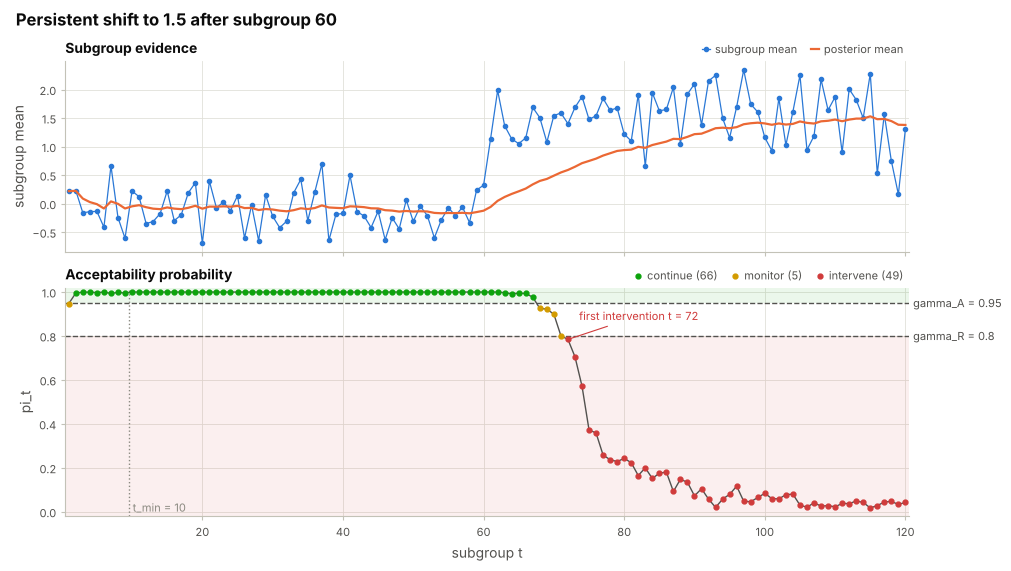

In [4]:
fig = r.plot(title="Persistent shift to 1.5 after subgroup 60")

The trajectory itself is in `r.frame`, one row per subgroup.

In [5]:
r.frame.loc[57:67, ["t", "mean", "mu_post", "sigma_post", "pi", "zone"]]

,t,mean,mu_post,sigma_post,pi,zone
57,58,-0.3310,-0.1686,0.9430,1.0000,continue
58,59,0.2374,-0.1473,0.9347,1.0000,continue
59,60,0.3246,-0.1225,0.9379,1.0000,continue
60,61,1.1410,-0.0565,0.9576,1.0000,continue
61,62,1.9848,0.0500,1.0452,1.0000,continue
62,63,1.3657,0.1185,1.0740,0.9970,continue
63,64,1.1347,0.1713,1.0981,0.9920,continue
64,65,1.0522,0.2170,1.0891,0.9945,continue
65,66,1.1534,0.2654,1.0925,0.9935,continue
66,67,1.6859,0.3388,1.1250,0.9765,continue


## 2. The settings are policy parameters

The defaults are the validation configuration of the article (Table 2): q<sub>0</sub> = 0.997
(Cpk ≈ 0.99 for a centred process), γ<sub>A</sub> = 0.95, γ<sub>R</sub> = 0.80, forgetting factor
λ<sub>f</sub> = 0.95, t<sub>min</sub> = 10. The article treats them as engineering and operational
policy parameters to be set for the application, not as universal constants. For a single decision,
intervening has the lower expected loss when π<sub>t</sub> ≤ c<sub>M</sub> / (c<sub>M</sub> + c<sub>I</sub>),
so γ<sub>R</sub> = 0.80 corresponds to a cost ratio c<sub>M</sub>/c<sub>I</sub> = 4.

In [6]:
for gamma_r in (0.5, 0.8, 0.9):
    ri = uccap.monitor_study(x, -4, 4, prior=(0, 1e-3, 2, 1), gamma_r=gamma_r)
    print(f"gamma_R = {gamma_r}: first intervention at subgroup {ri.intervention}")

gamma_R = 0.5: first intervention at subgroup 75
gamma_R = 0.8: first intervention at subgroup 72
gamma_R = 0.9: first intervention at subgroup 70


## 3. Many dimensions

`batch_monitor` takes the same inputs as `batch_study` (a file in the standard layout, a wide or long
table, a dict) and monitors every dimension with the tolerance-aware prior of the industrial replay:
centred at the nominal with scale (USL − LSL)/8. The four dimensions below follow the scenarios of
the article scaled to a tolerance of 10.00 ± 0.10.

In [7]:
rng = np.random.default_rng(2026)
t = np.repeat(np.arange(1, 121), 5)
sd = 0.025
data = pd.DataFrame({
    "M101": rng.normal(10.0, sd, t.size),                                         # stable
    "M102": rng.normal(10.0 + 0.0375 * (t > 60), sd),                             # shift to 1.5 sigma
    "M103": rng.normal(10.0 + 0.030 * ((t >= 45) & (t < 65)), sd),                # transient 1.2 sigma
    "M104": rng.normal(10.0, sd * np.where(t > 60, 1 + 0.8 * (t - 60) / 60, 1)),  # spread grows
})
specs = {d: {"lsl": 9.9, "usl": 10.1, "target": 10.0} for d in data}
batch = uccap.batch_monitor(data, specs)
batch.table(["dimension", "Ppk_normal", "pi_final", "pi_min", "first_intervention", "zone", "category"])

,dimension,Ppk_normal,pi_final,pi_min,first_intervention,zone,category
0,M101,1.2557,0.9995,0.9630,<NA>,continue,no intervention-zone entry
1,M102,0.9352,0.7545,0.1285,65,intervene,persistent low-confidence
2,M103,1.1561,0.9960,0.7285,57,continue,recovered transient
3,M104,1.0961,0.0950,0.0735,83,intervene,persistent low-confidence


The categories follow Table 14 of the article. M103 shows the boundary behaviour the article
reports: its transient state (mean 1.2σ off centre, q ≈ 0.9974) is still acceptable, yet the rule
entered the intervention zone before π recovered. M104 keeps its mean centred; the rule reacts to the
growing spread because q depends on σ as well.

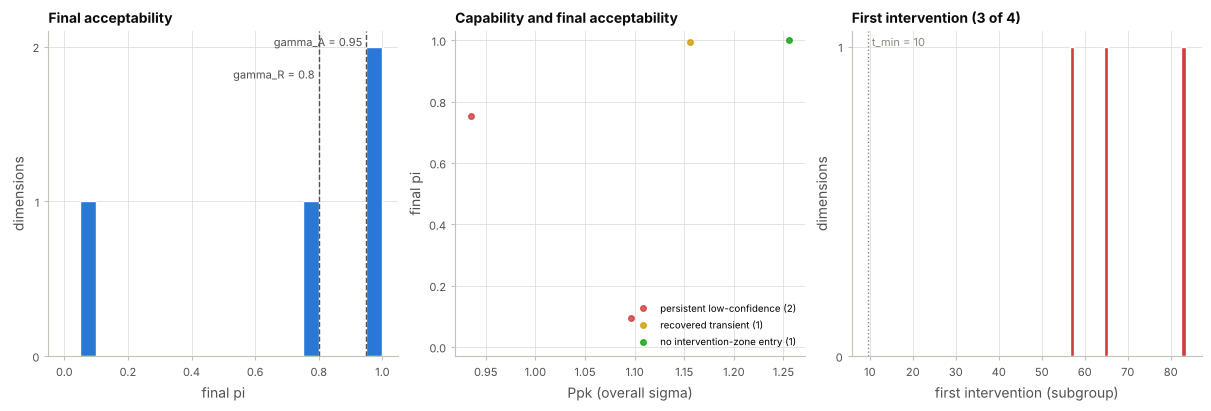

In [8]:
fig = batch.plot()

In [9]:
_ = batch.to_html("monitor_results.html")  # coloured table, sortable, with how the zones are set
# batch.to_excel("monitor_results.xlsx")   # adds the trajectory of every dimension

## 4. Scope

The Gaussian observation model is a working approximation: the article shows that skewed or
contaminated data, serial correlation and gauge error change how often the rule acts, above all for
states close to the boundary of the acceptable region. A first intervention at t<sub>min</sub> usually
means that π was already low at the start of the record, not that a change began there. The zones
support the engineer's decision after approval; they do not replace control charts or the approval
itself. From the command line: `uccap monitor production.xlsx --plots`.